# Customer Purchase Prediction — Machine Learning
**Author:** Hayet Mecegguem

## Objective
Train and compare classification models to predict whether a customer purchases a product using Age and EstimatedSalary.

Models: Logistic Regression, Decision Tree, Random Forest.
Metrics: Accuracy, Precision, Recall, F1-score, ROC-AUC, and confusion matrix.

This is an educational project using a small public sample dataset. Results should not be used for consequential decisions about real people.


## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
RANDOM_STATE = 42


## 2. Load dataset

In [6]:

import pandas as pd

# Load the Social Network Ads dataset
url = "https://huggingface.co/datasets/Rodrigopiva/Social_Network_Ads.csv/resolve/main/Social_Network_Ads.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


## 3. Explore and prepare data

Dataset shape: (400, 5)

Missing values:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Target distribution:
 Purchased
0    257
1    143
Name: count, dtype: int64


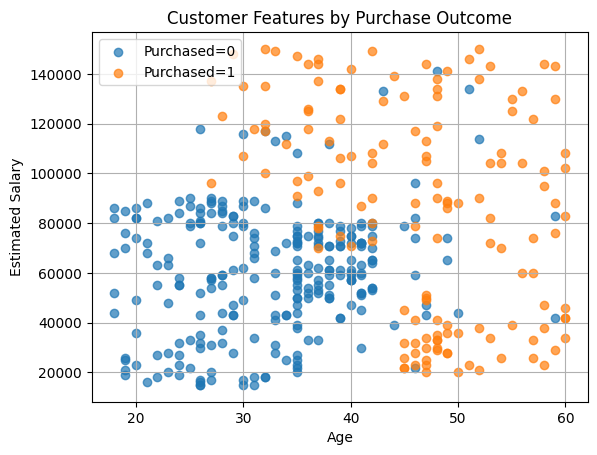

In [7]:
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nTarget distribution:\n", df["Purchased"].value_counts())

X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"].astype(int)

for label, group in df.groupby("Purchased"):
    plt.scatter(group["Age"], group["EstimatedSalary"], label=f"Purchased={label}", alpha=0.7)
plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.title("Customer Features by Purchase Outcome")
plt.legend()
plt.grid(True)
plt.show()


## 4. Split data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Training rows: 300 | Test rows: 100


## 5. Train and compare models

In [9]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
    ])
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(rows).sort_values("F1-score", ascending=False)
display(results.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Random Forest,0.91,0.865,0.889,0.877,0.930
1,Decision Tree,0.89,0.821,0.889,0.853,0.939
0,Logistic Regression,0.84,0.857,0.667,0.750,0.910


## 6. Confusion matrix for the best F1-score model

Best model by test F1-score: Random Forest
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        64
           1       0.86      0.89      0.88        36

    accuracy                           0.91       100
   macro avg       0.90      0.91      0.90       100
weighted avg       0.91      0.91      0.91       100



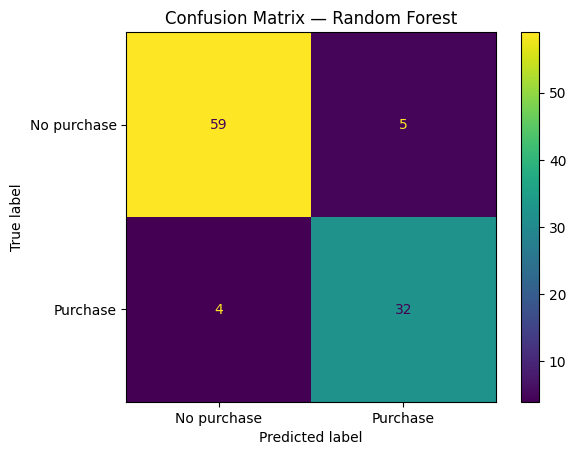

In [10]:
best_name = results.iloc[0]["Model"]
best_model = models[best_name]
best_pred = best_model.predict(X_test)

print("Best model by test F1-score:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["No purchase", "Purchase"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()


## 7. Cross-validation

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X, y, cv=cv,
        scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}
    )
    cv_rows.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std CV Accuracy": scores["test_accuracy"].std(),
        "Mean CV F1": scores["test_f1"].mean(),
        "Mean CV ROC-AUC": scores["test_roc_auc"].mean()
    })
cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV F1", ascending=False)
display(cv_results.round(3))


,Model,Mean CV Accuracy,Std CV Accuracy,Mean CV F1,Mean CV ROC-AUC
1,Decision Tree,0.898,0.035,0.856,0.941
2,Random Forest,0.885,0.035,0.839,0.940
0,Logistic Regression,0.842,0.023,0.758,0.926


## 8. Predict for a hypothetical example

In [12]:
example_customer = pd.DataFrame({"Age": [30], "EstimatedSalary": [50000]})
prediction = best_model.predict(example_customer)[0]
probability = best_model.predict_proba(example_customer)[0, 1]
print("Model:", best_name)
print("Prediction:", "Purchase" if prediction == 1 else "No purchase")
print(f"Estimated probability of purchase: {probability:.1%}")


Model: Random Forest
Prediction: No purchase
Estimated probability of purchase: 0.0%


In [13]:
# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Check data types
print("\nData types:")
print(df.dtypes)

# 4. Check statistical summary
print("\nStatistical summary:")
display(df.describe())

# 5. Check target distribution
print("\nPurchase distribution:")
print(df["Purchased"].value_counts())

# 6. Check invalid values
print("\nAge below 18:", (df["Age"] < 18).sum())
print("Age above 100:", (df["Age"] > 100).sum())
print("Negative salaries:", (df["EstimatedSalary"] < 0).sum())

# 7. Check gender categories
print("\nGender categories:")
print(df["Gender"].value_counts())

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Number of duplicate rows:
0

Data types:
User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object

Statistical summary:


,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000



Purchase distribution:
Purchased
0    257
1    143
Name: count, dtype: int64

Age below 18: 0
Age above 100: 0
Negative salaries: 0

Gender categories:
Gender
Female    204
Male      196
Name: count, dtype: int64


In [14]:
# 1. Check unique values in the target column
print("Unique values in Purchased:")
print(sorted(df["Purchased"].unique()))

# 2. Check unique values in Gender
print("\nUnique values in Gender:")
print(df["Gender"].unique())

# 3. Check whether User ID values are unique
print("\nNumber of unique User IDs:")
print(df["User ID"].nunique())

# 4. Check outliers using the IQR method
for column in ["Age", "EstimatedSalary"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))

Unique values in Purchased:
[np.int64(0), np.int64(1)]

Unique values in Gender:
['Male' 'Female']

Number of unique User IDs:
400

Column: Age
Lower bound: 5.375
Upper bound: 70.375
Number of potential outliers: 0

Column: EstimatedSalary
Lower bound: -24500.0
Upper bound: 155500.0
Number of potential outliers: 0


## 9. Conclusions and limitations

After running the notebook, use your actual results to answer:
1. Which model performed best on the test set?
2. Did cross-validation show a similar pattern?
3. What kinds of errors appear in the confusion matrix?
4. Why is F1-score useful alongside accuracy?

**Limitations:** This is a small, simplified educational dataset using only Age and EstimatedSalary. Results may not generalize to real customer populations. Do not use this model to make consequential decisions about individuals.

### Possible extensions
- Add more appropriate features if available.
- Tune hyperparameters with cross-validation.
- Compare precision-recall curves.
- Create a README with your actual results and plots.
